<a href="https://colab.research.google.com/github/lucassoaresdeoliveira07-afk/analise-reviews-simrmtc/blob/main/WebS_sim_rmtc.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Data: 04/11/2026
- Projeto de Análise dos Comentários da Google Play Store sobre o aplicativo SIM RMTC

# preparação do ambiente

In [1]:
#
# https://github.com/Mohammedcha/gplay-scraper

!pip install gplay-scraper
!pip install curl-cffi

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

from gplay_scraper import GPlayScraper, Config
from tqdm import tqdm

Config.RATE_LIMIT_DELAY = 2.0
Config.DEFAULT_TIMEOUT = 30
Config.DEFAULT_RETRY_COUNT = 5

scraper = GPlayScraper(http_client="curl_cffi")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.7/7.7 MB 27.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.5/8.5 MB 69.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [gplay-scraper]


# raspagem

In [2]:
get_review = scraper.app_analyze('br.com.consorciormtc.amip002', lang="pt", country="br")
get_review

{'appId': 'br.com.consorciormtc.amip002',
 'title': 'SiMRmtc',
 'summary': 'O SiMRmtc é o único que oferece um canal de relacionamento direto com a RMTC',
 'description': 'O aplicativo SiMRmtc é uma excelente ferramenta de mobilidade urbana, através dele você pode acompanhar o deslocamento dos veículos da Região Metropolitana de Goiânia em tempo real. O GPS do celular reconhece sua localização e mostra os pontos de ônibus próximos e os locais de venda de recarga do cartão Sitpass. \n\nAo clicar no ponto desejado aparecem os horários dos dois próximos veículos por linha que passarão por ali.\n\nAlém disso, o aplicativo oferece também o serviço planeje sua viagem, onde você pode, a partir da informação de um endereço de origem e de destino, descobrir as linhas de ônibus disponíveis para te conectar ao seu destino, com todo o detalhamento de horários das viagens, tempos de deslocamento, locais de embarque e desembarque e integrações com outras linhas, quando necessário.\n\nO SiMRmtc é o ú

In [3]:
apps_ids = [
    'br.com.consorciormtc.amip002'
]

content = []

for app_id in tqdm(apps_ids):
    avaliacoes = scraper.reviews_analyze(
        app_id,
        count=10000,
        sort="NEWEST",
        lang="pt",
        country="br"
    )
    if not avaliacoes:
        print(f"Nenhuma review encontrada para {app_id}")
        continue
    for review in avaliacoes:
        content.append({
          'reviewId': review['reviewId'],
          'score': review['score'],
          'content': review['content'],
          'thumbsUpCount': review['thumbsUpCount'],
          'appVersion': review['appVersion'],
          'at': review['at']
})


print(len(content), "avaliações coletadas")

100%|██████████| 1/1 [02:34<00:00, 154.27s/it]

3882 avaliações coletadas


In [4]:
content

[{'reviewId': '163089fd-49b2-4f7c-b705-06c443fe496e',
  'score': 1,
  'content': 'muito difícil acesso nos pontos de ônibus',
  'thumbsUpCount': 0,
  'appVersion': '1.7.4',
  'at': '2026-11-03T07:58:56'},
 {'reviewId': '20f12b7b-532f-40c8-942d-99262a43f29e',
  'score': 3,
  'content': 'plmds, cadê as atualizações desse aplicativo? cada dia fica pior, as vezes não aparece os pontos que você deixou nos favoritos',
  'thumbsUpCount': 0,
  'appVersion': '1.7.4',
  'at': '2026-11-03T03:15:50'},
 {'reviewId': '065475c2-d880-4c33-9494-41c19a98eb66',
  'score': 1,
  'content': 'App horrível, no aplicativo diz que o bus não passou porém ele ja passou e você fica lá esperando... péssimo.',
  'thumbsUpCount': 0,
  'appVersion': None,
  'at': '2026-10-30T23:37:17'},
 {'reviewId': '29d1ec34-bcf8-41fc-bbb7-30a02f2c694e',
  'score': 1,
  'content': 'aplicativo mostra o ônibus em tempo real,mais só na teoria, porque o ônibus não passa no ponto, não dá pra confiar, no terminal e a mesma coisa ,vê o ôni

# DataFrame

In [5]:
df = pd.DataFrame(content)
df = df.drop_duplicates(subset='reviewId')   # remove avaliações repetidas
df['at'] = pd.to_datetime(df['at'])          # converte a data

df.to_csv('reviews_simrmtc.csv', index=False, encoding='utf-8')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3882 entries, 0 to 3881
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   reviewId       3882 non-null   object        
 1   score          3882 non-null   int64         
 2   content        3880 non-null   object        
 3   thumbsUpCount  3882 non-null   int64         
 4   appVersion     3209 non-null   object        
 5   at             3882 non-null   datetime64[ns]
dtypes: datetime64[ns](1), int64(2), object(3)
memory usage: 182.1+ KB


In [6]:
df.shape
print(f'Quantidade de linhas: {df.shape[0]}')
print(f'Quantidade de colunas: {df.shape[1]}')

Quantidade de linhas: 3882
Quantidade de colunas: 6


In [7]:
print("Textos vazios ou só com espaços:", (df["content"].str.strip() == "").sum())
print("reviewId duplicado:", df.duplicated(subset="reviewId").sum())
print("Mesmo texto e mesma nota (avaliações diferentes):", df.duplicated(subset=["content", "score"]).sum())

Textos vazios ou só com espaços: 0
reviewId duplicado: 0
Mesmo texto e mesma nota (avaliações diferentes): 605


# Análises iniciais

In [8]:
# Textos repetidos mais frequentes
df[df.duplicated(subset=["content", "score"])]["content"].str.lower().value_counts().head(15)

,count
content,
bom,138
muito bom,137
ótimo,94
otimo,35
top,19
excelente,17
ótima,14
boa,14
ok,10


In [9]:
# Período das avaliações:

# Convertendo a coluna 'at' para datetime para permitir cálculos de data
df['at'] = pd.to_datetime(df['at'])

print("Avaliação mais antiga:", df['at'].min())
print("Avaliação mais recente:", df['at'].max())
print("Dias cobertos:", (df['at'].max() - df['at'].min()).days)

Avaliação mais antiga: 2015-03-20 17:14:49
Avaliação mais recente: 2026-11-03 07:58:56
Dias cobertos: 4245


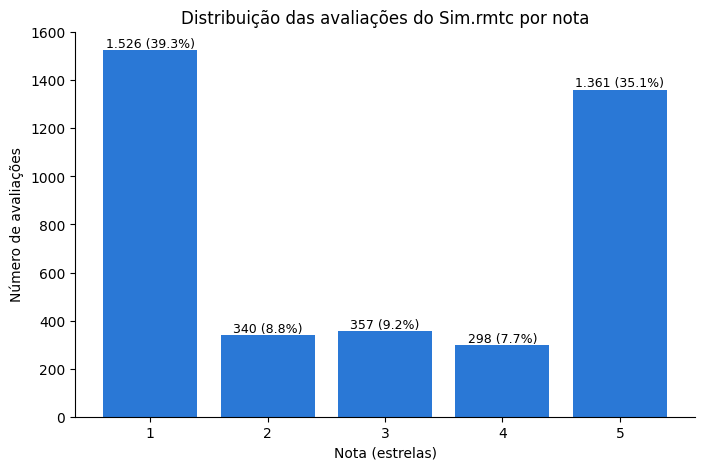

In [10]:
# Gráfico das notas

contagem = df["score"].value_counts().reindex([1, 2, 3, 4, 5], fill_value=0)
percentual = (contagem / contagem.sum() * 100).round(1)

fig, ax = plt.subplots(figsize=(8, 5))
barras = ax.bar(contagem.index, contagem.values, color="#2a78d6")
ax.bar_label(barras, labels=[f"{n:,} ({p}%)".replace(",", ".") for n, p in zip(contagem, percentual)], fontsize=9)
ax.set_xticks([1, 2, 3, 4, 5])
ax.set_xlabel("Nota (estrelas)")
ax.set_ylabel("Número de avaliações")
ax.set_title("Distribuição das avaliações do Sim.rmtc por nota")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

In [11]:
import re
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


# Pré-Processamento textual

In [12]:
# stopwords em português, mas mantendo as negações
stop_pt = set(stopwords.words('portuguese'))
negacoes = {'não', 'nem', 'nunca', 'nada', 'ninguém', 'sem'}
stop_pt = stop_pt - negacoes

def limpar_texto(texto):
    if not isinstance(texto, str):
        return ''
    texto = texto.lower()                                # tudo minúsculo
    texto = re.sub(r'http\S+|www\.\S+', ' ', texto)      # remove links
    texto = re.sub(r'\d+', ' ', texto)                   # remove números
    texto = re.sub(r'[^a-zà-ú\s]', ' ', texto)           # remove pontuação e emojis (mantém acentos)
    palavras = texto.split()
    palavras = [p for p in palavras if p not in stop_pt and len(p) > 2]
    return ' '.join(palavras)

# remove avaliações sem texto
df = df.dropna(subset=['content'])

In [13]:
df['content_limpo'] = df['content'].apply(limpar_texto)
df[['content', 'content_limpo']].sample(10)

,content,content_limpo
602,O aplicativo nao abre a dois dias,aplicativo nao abre dois dias
1976,Aplicativo horrivel numca funciona nas hrs cer...,aplicativo horrivel numca funciona hrs certo s...
3871,Muito bom,bom
1350,Eu gosto muito dele,gosto
120,"app já foi bom, um dia! você acompanha o horár...",app bom dia acompanha horário ônibus app esper...
281,comodidade e muito bom,comodidade bom
1869,Toppp,toppp
2669,"está dando erro desconhecido, arrumem isso por...",dando erro desconhecido arrumem favor
3875,"Ajuda a saber os locais de venda do Sitpass, o...",ajuda saber locais venda sitpass onde pegar ôn...
504,A versão mais recente não funciona bem. Tenho ...,versão recente não funciona bem desinstalar in...


In [14]:
!pip install unidecode
from unidecode import unidecode

# tira os acentos das stopwords também
stop_pt = {unidecode(p) for p in stopwords.words('portuguese')}
negacoes = {'nao', 'nem', 'nunca', 'nada', 'ninguem', 'sem'}
stop_extra = {'app', 'aplicativo', 'pra', 'pro', 'mto', 'vai', 'esta'}

stop_final = (stop_pt - negacoes) | stop_extra

def limpar_texto(texto):
    if not isinstance(texto, str):
        return ''
    texto = unidecode(texto.lower())                     # minúsculo e sem acento
    texto = re.sub(r'http\S+|www\.\S+', ' ', texto)
    texto = re.sub(r'\d+', ' ', texto)
    texto = re.sub(r'[^a-z\s]', ' ', texto)              # agora só letras sem acento
    palavras = [p for p in texto.split() if p not in stop_final and len(p) > 2]
    return ' '.join(palavras)

df['content_limpo'] = df['content'].apply(limpar_texto)
df[['content', 'content_limpo']].sample(10)

,content,content_limpo
2075,Ótimo,otimo
2298,E otmo pra n fkar esperando mt tmpo no pnto,otmo fkar esperando tmpo pnto
1574,Boa,boa
2248,Funciona afinal.,funciona afinal
1413,Deveria ter a opção no App de consultar Saldo ...,deveria ter opcao consultar saldo fazer recarg...
1570,Bom de mais... O app os onibus pecimos,bom onibus pecimos
356,terrível experiência com o App,terrivel experiencia
643,Muito bom,bom
2940,ótimo amei,otimo amei
713,O que houve com o aplicativo no dia de hoje (1...,dia hoje nao abre clicar sobre nao aparece nada


In [15]:
(df['content_limpo'] == '').sum()

np.int64(34)

In [16]:
df.loc[df['content_limpo'] == '', ['content', 'score']]

,content,score
403,Ok,2
448,Ok,1
466,Ok,5
607,Está fora do ar,1
864,👍,5
993,👍,5
1012,E o que vc tem,2
1073,Ok,5
1278,Ok,4
1395,Cú,1


In [17]:
df_texto = df[df['content_limpo'] != ''].copy()
print(len(df), "avaliações no total")
print(len(df_texto), "avaliações com texto útil para BoW/TF-IDF")

3880 avaliações no total
3846 avaliações com texto útil para BoW/TF-IDF


# Análises textuais básicas

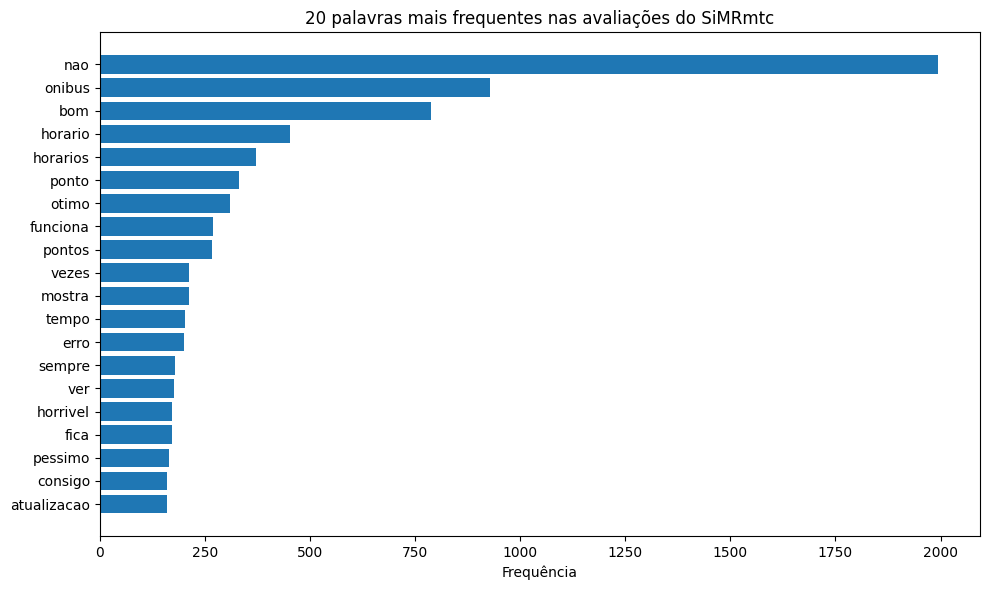

In [18]:
# Frequências de Palavras

from collections import Counter
import matplotlib.pyplot as plt

def contar_palavras(serie, n=20):
    todas = ' '.join(serie).split()
    return Counter(todas).most_common(n)

top_geral = contar_palavras(df_texto['content_limpo'])

palavras, freq = zip(*top_geral)
plt.figure(figsize=(10, 6))
plt.barh(palavras[::-1], freq[::-1])
plt.title('20 palavras mais frequentes nas avaliações do SiMRmtc')
plt.xlabel('Frequência')
plt.tight_layout()
plt.show()

In [20]:
from wordcloud import WordCloud

# Definindo variáveis de exemplo caso não estejam declaradas
texto = ' '.join(df_texto['content_limpo'])
cor = 'Blues'

nuvem = WordCloud(width=800, height=600, background_color='white',
                  colormap=cor, max_words=80,
                  normalize_plurals=False,   # não corta o "s" final
                  collocations=True          # mantém os bigramas
                  ).generate(texto)

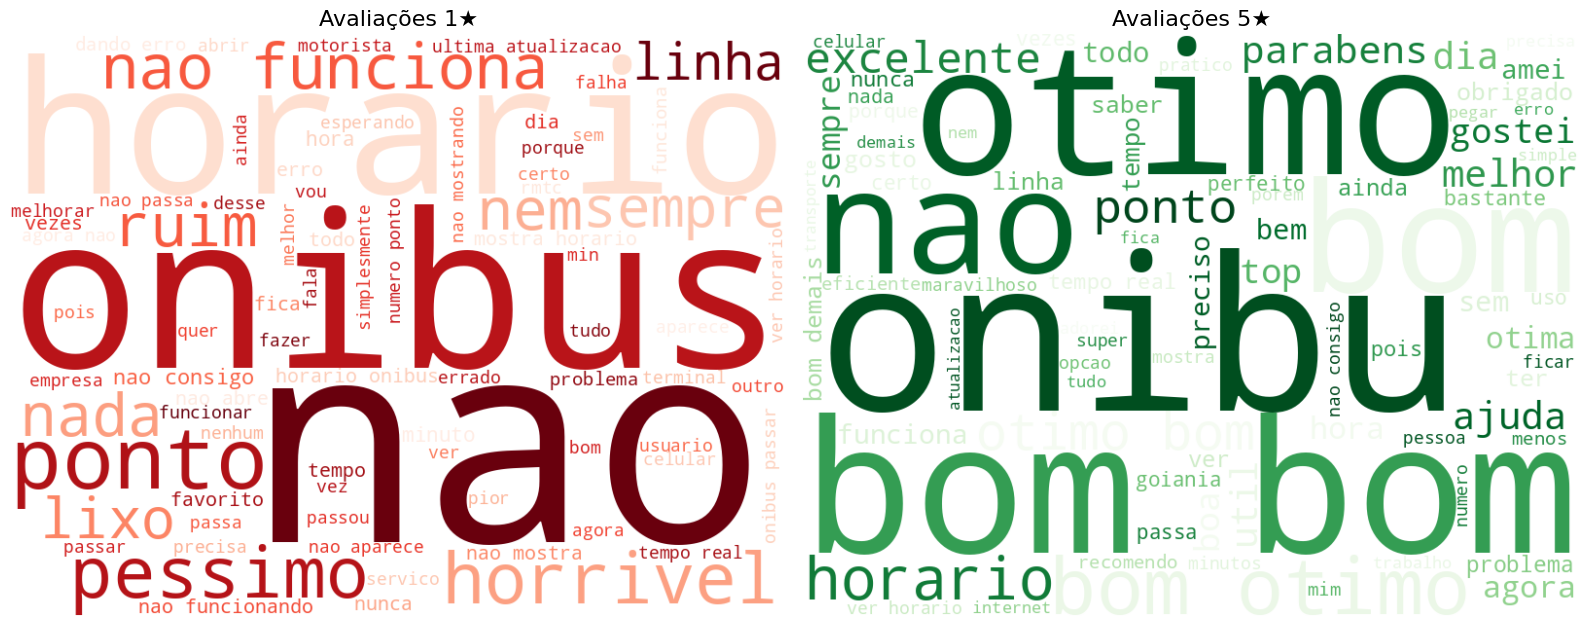

In [24]:
# Nuvem de Palavras

from wordcloud import WordCloud

negativas = ' '.join(df_texto.loc[df_texto['score'] == 1, 'content_limpo'])
positivas = ' '.join(df_texto.loc[df_texto['score'] == 5, 'content_limpo'])

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, texto, titulo, cor in [
    (axes[0], negativas, 'Avaliações 1★', 'Reds'),
    (axes[1], positivas, 'Avaliações 5★', 'Greens')
]:
    nuvem = WordCloud(width=800, height=600, background_color='white',
                      colormap=cor, max_words=80).generate(texto)
    ax.imshow(nuvem, interpolation='bilinear')
    ax.set_title(titulo, fontsize=16)
    ax.axis('off')

plt.tight_layout()
plt.savefig('novem_de_palavras.png', dpi=150, bbox_inches='tight')
plt.show()

In [22]:
df['score'].value_counts().sort_index()

,count
score,
1,1526
2,340
3,357
4,298
5,1359


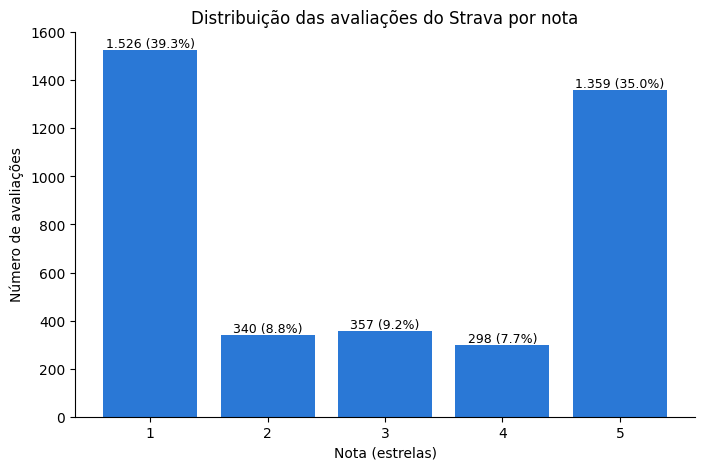

In [25]:
# Gráfico das notas

contagem = df["score"].value_counts().reindex([1, 2, 3, 4, 5], fill_value=0)
percentual = (contagem / contagem.sum() * 100).round(1)

fig, ax = plt.subplots(figsize=(8, 5))
barras = ax.bar(contagem.index, contagem.values, color="#2a78d6")
ax.bar_label(barras, labels=[f"{n:,} ({p}%)".replace(",", ".") for n, p in zip(contagem, percentual)], fontsize=9)
ax.set_xticks([1, 2, 3, 4, 5])
ax.set_xlabel("Nota (estrelas)")
ax.set_ylabel("Número de avaliações")
ax.set_title("Distribuição das avaliações do Strava por nota")
ax.spines[["top", "right"]].set_visible(False)
plt.savefig('distribuição.png', dpi=150, bbox_inches='tight')